# 2. Comparing global and periodic STM grey boxes

The six states are position and velocity departure from the nominal NRHO. In corridor-scaled coordinates,

$$e_{k+1}=A_k e_k+B_k\operatorname{diag}(g(\phi_k))u_k+w_k,\qquad z_{j,k}=h_j(t_k,x_{\rm nom}(t_k))+C_{j,k}e_k+v_{j,k},$$
$$\dot\Phi=F(t)\Phi,\quad A_k=J^{-1}\Phi(t_{k+1},t_k)J,\quad C_{j,k}=\left.\frac{\partial h_j}{\partial x}\right|_{x_{\rm nom}(t_k)}J.$$

$z_{j,k}$ contains the two angles from visible LSO $j$, so **$C_{j,k}$ is not the identity**. The measurement noise enters additively after the ideal angle map: $v_{j,k}\sim\mathcal{N}(0,R)$ with $R=\sigma_\theta^2 I_2$ and $\sigma_\theta=1$ arcsec in the synthetic sensor generator. Draws are independent across angle components, sites and epochs, which is a white-noise assumption. No real sensor calibration data are used to justify white or Gaussian noise, and bias or colored noise are not modeled. The innovation tests check this assumption against the synthetic data. Known physics fixes the repeatable $A_k$ and $B_k$ along the nominal orbit. The global baseline fits one set of three mean gains. The periodic fit replaces $g$ with $g(\phi_k)$, an interpolation of overlapping phase windows. The last window blends into the first. The simulator uses constant physical gains, so any fitted phase variation represents effective model correction rather than changing actuator hardware.

In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display, Markdown
from halo_tracking import stationkeeping as physics
from halo_tracking import lso_stationkeeping as sk
from halo_tracking import stationkeeping_diagnostics as sd
from halo_tracking import lso_diagnostics as ld
from halo_tracking import lso_report_plots as plots
ROOT=Path.cwd()
if not (ROOT/'configs').exists(): ROOT=ROOT.parent
OUT=ROOT/'artifacts'/'stationkeeping'
OUT.mkdir(parents=True,exist_ok=True)
plots.style()
def table(headers,rows):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
                     '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))

orbit,data=sk.restore_study(ROOT,OUT/'data')
global_fit=sk.fit_greybox(orbit,data['training'])
fit=sk.fit_periodic_greybox(orbit,data['training'],
    windows=orbit.settings['periodic_gain_windows'],
    smoothing=orbit.settings['periodic_gain_smoothing'])
gains=fit['gains']
models={'Global gains':global_fit['gains'],'Periodic gains':gains}
table(['Phase [deg]','X gain','Y gain','Z gain'],
      [(f'{phase:.0f}',*(f'{value:.4f}' for value in local))
       for phase,local in zip(fit['knot_phase_deg'],fit['knot_gains'])])
print('Global gains:',global_fit['gains'])

def save_fit(name, result):
    values={k:v.tolist() if isinstance(v,np.ndarray) else v for k,v in result.items()}
    (OUT/name).write_text(json.dumps(values,indent=2)+'\n')

save_fit('greybox_fit.json',fit)
save_fit('global_greybox_fit.json',global_fit)

Global gains: [0.98926964 1.03752362 0.95475192]


| Phase [deg] | X gain | Y gain | Z gain |
| --- | --- | --- | --- |
| 0 | 0.9584 | 1.0745 | 1.0392 |
| 60 | 0.9866 | 1.0463 | 1.0367 |
| 120 | 0.9968 | 1.0497 | 1.0139 |
| 180 | 0.9837 | 1.0587 | 0.9111 |
| 240 | 0.9929 | 1.0154 | 0.9927 |
| 300 | 0.9808 | 1.0354 | 1.0255 |

## Identification and held-out validation

Following Studios 5 and 11, minimize covariance-standardized **raw angular innovations** on training trajectories, updating only when an LSO is visible. No generated full-state observations or saved truth enter the fit. Filtered state histories are correlated outputs, so they support exploratory plots and guidance, not independent-measurement regression.

Both variants use the same training, validation and test trajectories. Lecture 13 motivates a local approximation when full-record stationarity is doubtful. Here windows are indexed by orbital phase, so training can pool repeated passages through the same phase. Adjacent gains are regularized towards one another, with no test-driven choice of window count. Independent test trajectories assess angular prediction and navigation accuracy. Free propagation uses its initial angular update and then the known commands, with no later measurements. Truth is used only to evaluate state errors.

| Split | Model | Angular RMSE [arcsec] | Navigation position RMSE [km] | Navigation velocity RMSE [m/s] |
| --- | --- | --- | --- | --- |
| validation | Global gains | 2.23 | 0.391 | 0.00474 |
| test | Global gains | 2.44 | 0.372 | 0.00414 |
| validation | Periodic gains | 2.28 | 0.411 | 0.00481 |
| test | Periodic gains | 2.43 | 0.371 | 0.00411 |

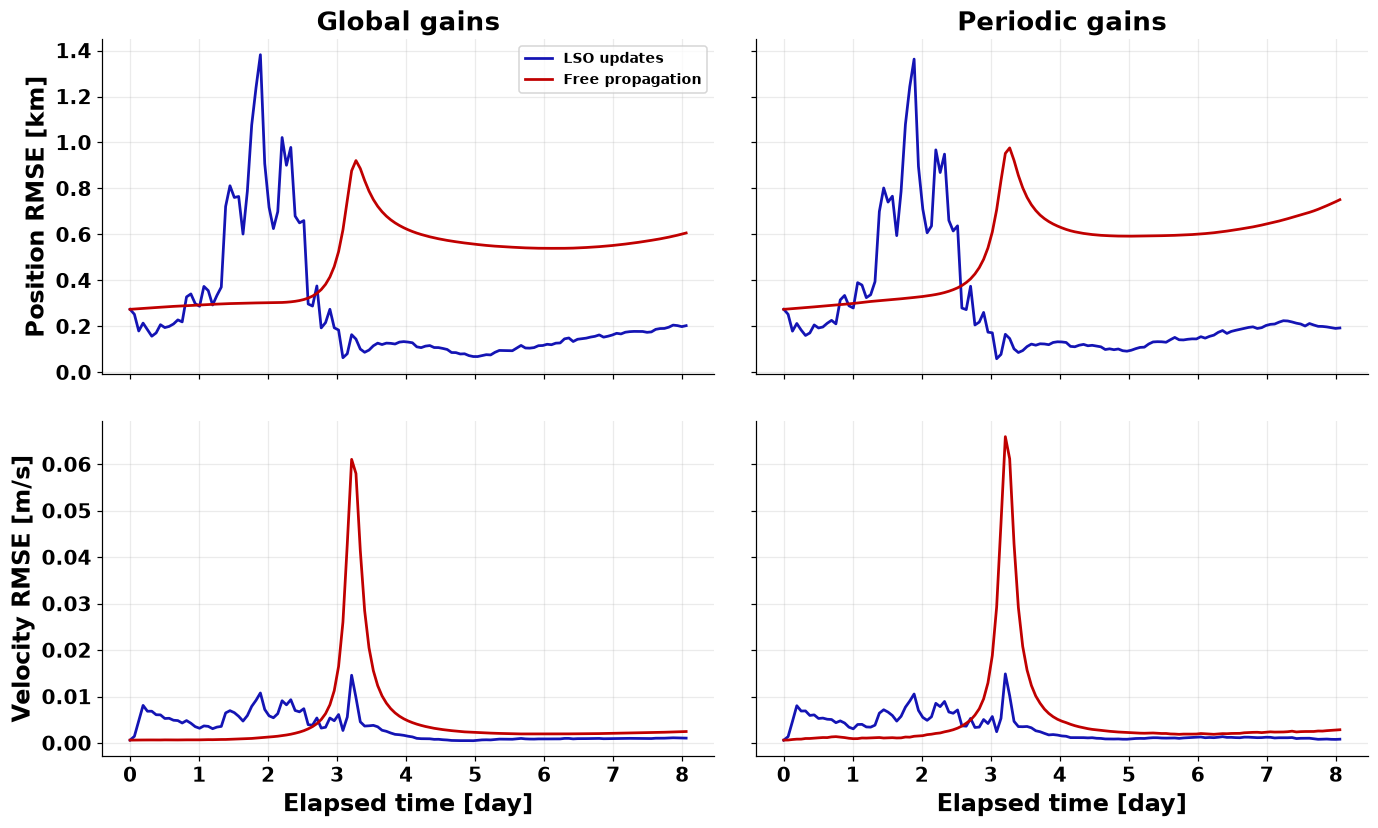

**Purpose:** Shared scales compare held-out prediction errors for the same trajectories.

**Result:** The blue traces show how LSO updates change the state errors for each fitted gain model.

In [2]:
scores={model:{split:sk.prediction_scores(orbit,rec,model_gains) for split,rec in data.items()}
        for model,model_gains in models.items()}
table(['Split','Model','Angular RMSE [arcsec]','Navigation position RMSE [km]','Navigation velocity RMSE [m/s]'],
      [(split,model,f"{q['angular_innovation_rmse_arcsec']:.3g}",
        f"{q['navigation']['position_rmse_km']:.3g}",f"{q['navigation']['velocity_rmse_m_s']:.3g}")
       for model,result in scores.items() for split,q in result.items() if split != 'training'])
(OUT/'prediction_scores.json').write_text(json.dumps(scores['Periodic gains'],indent=2)+'\n')
(OUT/'model_comparison_scores.json').write_text(json.dumps(scores,indent=2)+'\n')
test=data['test']
predictions={label:(sk.predict(orbit,test,local),sk.predict(orbit,test,local,free_run=True))
             for label,local in models.items()}
pred,free=predictions['Periodic gains']
plots.compare_heldout(orbit,test,predictions,OUT/'figures')
np.savez_compressed(OUT/'test_predictions.npz',**pred,free_simulation=free['navigation'])

## Do the residuals support the predictor?

Use standardized angular innovations with actual time lags and visibility gaps intact. Ljung–Box uses eligible contiguous runs with Holm adjustment. A mask-conditioned Monte Carlo maximum-CCF test covers the input/channel/lag family. No gaps or independent trajectories are concatenated, and no fitted ARMA degrees of freedom are subtracted for the fixed model on test data.

ADF and KPSS use the longest uninterrupted observed run for each channel. The table reports the channels that support testing. A coverage summary reports any channels left out. Residual whiteness checks the adequacy of the assumed noise model. Residual–input correlation checks whether commanded impulses remain related to the prediction error. Controller performance is evaluated separately using the corridor limits.

Out[3]: 76


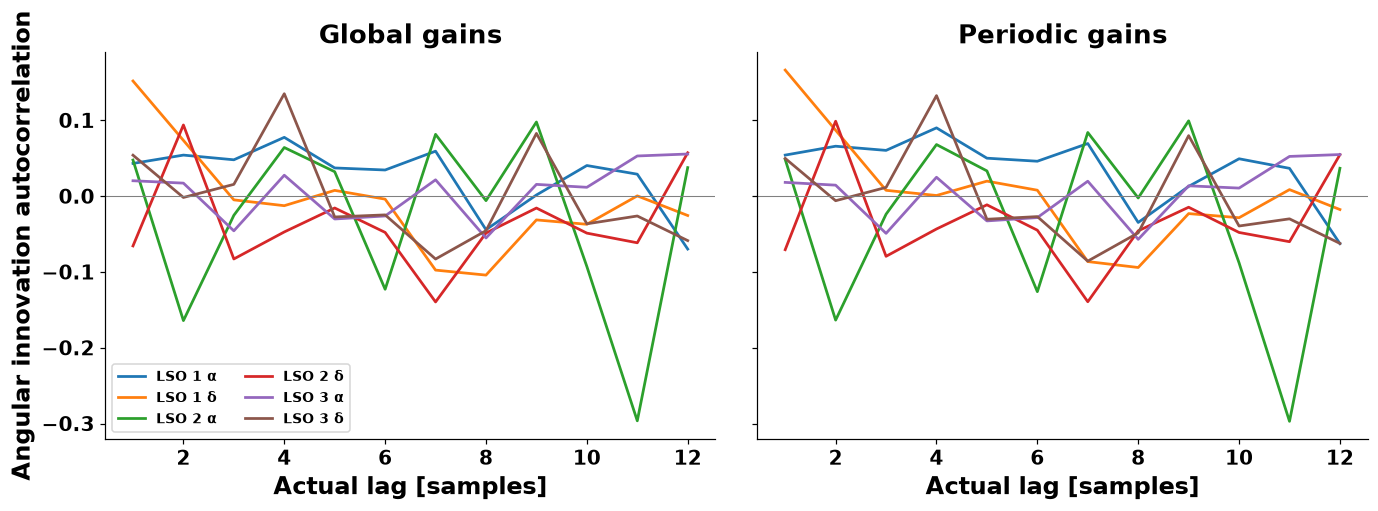

**Purpose:** Common lag and correlation scales compare innovation autocorrelation while preserving gaps.

**Result:** Global gains reject whiteness in 0 of 24 eligible runs. Periodic gains reject whiteness in 0 of 24 eligible runs.

| Model | Ljung–Box rejects | Eligible runs | Input–innovation p |
| --- | --- | --- | --- |
| Global gains | 0 | 24 | 0.72 |
| Periodic gains | 0 | 24 | 0.685 |

| Angular channel | Contiguous samples | ADF p | KPSS p | Joint reading |
| --- | --- | --- | --- | --- |
| LSO 1 alpha | 63 | 0.494 | 0.0847 | inconclusive / low power |
| LSO 1 delta | 63 | 5.27e-14 | 0.1 | supports level stationarity |
| LSO 2 alpha | 30 | 0.00773 | 0.0424 | conflicting tests |
| LSO 2 delta | 30 | 0.000369 | 0.1 | supports level stationarity |
| LSO 3 alpha | 71 | 0.904 | 0.01 | evidence against level stationarity |
| LSO 3 delta | 71 | 1.36e-12 | 0.1 | supports level stationarity |

**Angular stationarity coverage:** All 6 channels meet the contiguous-sample requirement. The table reports the periodic fit.

In [3]:
reports={label:ld.residual_report(updated['standardized'],test.u,orbit.settings['residual_lags'])
         for label,(updated,_) in predictions.items()}
residual=reports['Periodic gains']
plots.compare_angular_residuals(reports,OUT/'figures')
table(['Model','Ljung–Box rejects','Eligible runs','Input–innovation p'],
      [(label,int(np.nansum(q['ljung_box_holm_p']<orbit.settings['alpha'])),
        q['eligible_whiteness_tests'],f"{q['ccf_global_p']:.3g}")
       for label,q in reports.items()])
stationarity_rows=ld.stationarity_rows(pred['standardized'])
tested=[r for r in stationarity_rows if r['adf_p'] is not None and r['kpss_p'] is not None]
if tested:
    table(['Angular channel','Contiguous samples','ADF p','KPSS p','Joint reading'],
          [(r['channel'],r['contiguous_samples'],f"{r['adf_p']:.3g}",
            f"{r['kpss_p']:.3g}",r['reading']) for r in tested])
    if len(tested)==len(stationarity_rows):
        display(Markdown(f'**Angular stationarity coverage:** All {len(tested)} channels meet the contiguous-sample requirement. The table reports the periodic fit.'))
skipped=[r for r in stationarity_rows if r['adf_p'] is None or r['kpss_p'] is None]
if skipped:
    sites=', '.join(sorted({r['channel'].rsplit(' ',1)[0] for r in skipped}))
    counts=[r['contiguous_samples'] for r in skipped]
    coverage=str(min(counts)) if min(counts)==max(counts) else f'{min(counts)}–{max(counts)}'
    display(Markdown(f'**Angular stationarity coverage:** Tested {len(tested)} of {len(stationarity_rows)} channels. '
                     f'The {len(skipped)} skipped channels ({sites}) had longest observed runs of {coverage} '
                     f'consecutive samples. ADF and KPSS require at least {ld.ANGULAR_STATIONARITY_MIN_SAMPLES} here.'))
(OUT/'innovation_stationarity.json').write_text(json.dumps(stationarity_rows,indent=2)+'\n')
np.savez_compressed(OUT/'residual_checks.npz',**{k:v for k,v in residual.items() if isinstance(v,np.ndarray)})
(OUT/'optical_residual_summary.json').write_text(json.dumps({k:v for k,v in residual.items() if not isinstance(v,np.ndarray)},indent=2)+'\n')

## Does the gain model change full-year station-keeping?

Guidance uses only the LSO-derived departure estimate, with state updates at every measurement sample and planner calls at every measurement sample (about 1.5 hours). Candidate burns are checked by nonlinear propagation. The one-year run reports sampled corridor performance and the cumulative commanded Δv from the actual simulated impulses.

Both runs use the revised extended navigation filter and the same single-burn planner, which targets 30% of the corridor limits. The filter propagates the estimated state with nonlinear dynamics, recomputes its local STM and visible angle Jacobians, and accounts for impulse uncertainty. The initial departure, angle-noise seed and measurement cadence are fixed. The side-by-side plots isolate the choice of a global or periodic actuator gain fit for this simulated year.

| Gains with revised filter | Completed | First exit [day] | Peak position [km] | Peak velocity [m/s] | Burns | Commanded Δv [m/s] |
| --- | --- | --- | --- | --- | --- | --- |
| Global gains | Yes | No exit | 3.05 | 0.0846 | 395 | 6.47 |
| Periodic gains | Yes | 91.8 | 3.18 | 0.106 | 431 | 6.8 |

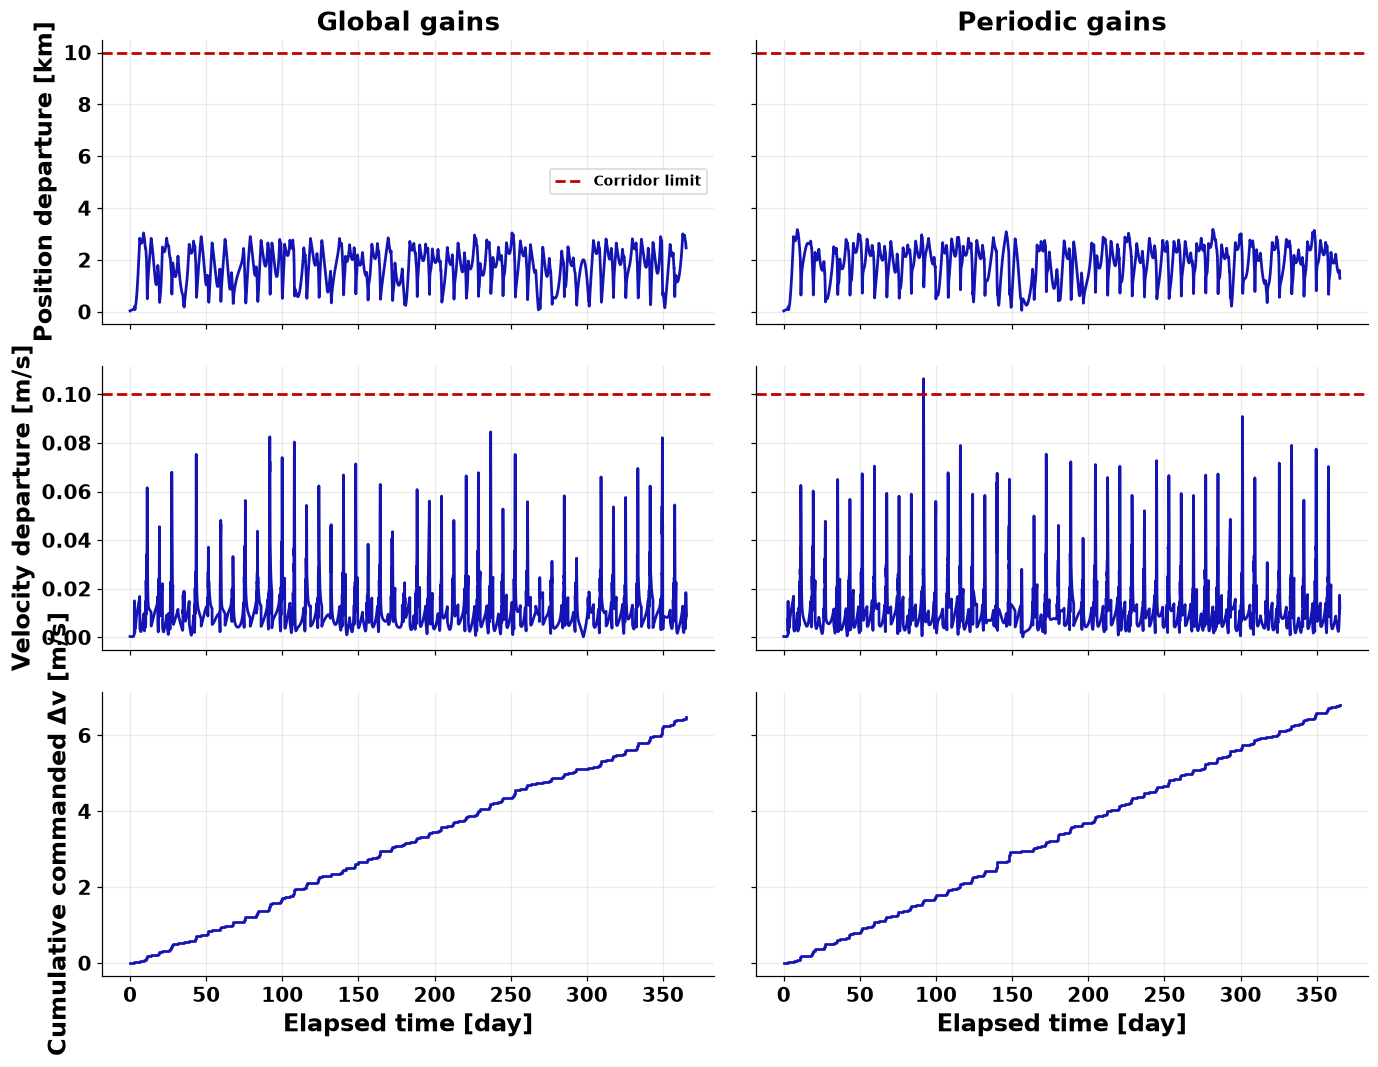

**Purpose:** Compare true departures and accumulated commands with the same filter, planner and starting conditions.

**Result:** Global gains stayed inside both limits and commanded 6.47 m/s. Periodic gains did not meet the full-year corridor and commanded 6.8 m/s.

| Metric | Observed value |
| --- | --- |
| completed | True |
| requested_duration_days | 365.25 |
| last_day | 365.25 |
| planning_stride_steps | 1 |
| planning_margin | 0.3 |
| maximum_position_km | 3.182267050662951 |
| maximum_velocity_m_s | 0.10644446132044358 |
| all_evaluated_samples_inside | False |
| first_sampled_exit_day | 91.78648573938327 |
| burns | 431 |
| total_commanded_delta_v_m_s | 6.804879163468829 |
| annual_delta_v_m_s | 6.804879163468829 |
| visible_epoch_fraction | 0.9960358497069975 |

**Noise-model conclusion:** 0/24 eligible whiteness tests reject after adjustment and the global residual–input p-value is 0.685, so these tests do not reject the tested assumptions at 5%, without proving the model correct.

**Full-year corridor compliance:** Global gains. This is a paired comparison for one starting departure and one observation-noise seed.

In [4]:
trials={model:sk.stationkeeping_trial(
    orbit,model_gains, navigation='extended', seed=26960,
    duration_days=orbit.settings['annual_horizon_days'],
    planning_stride_steps=orbit.settings['annual_planning_stride_steps'],
    stop_on_departure_cutoff=False)
    for model,model_gains in models.items()}
trial=trials['Periodic gains']
comparison={model:result['summary'] for model,result in trials.items()}
(OUT/'annual_model_comparison.json').write_text(json.dumps(comparison,indent=2)+'\n')
def annual_metric(value):
    return '—' if value is None else f'{value:.3g}'
table(['Gains with revised filter','Completed','First exit [day]','Peak position [km]',
       'Peak velocity [m/s]','Burns','Commanded Δv [m/s]'],
      [(model,'Yes' if q['completed'] else 'No',
        'No exit' if q['first_sampled_exit_day'] is None else annual_metric(q['first_sampled_exit_day']),
        annual_metric(q['maximum_position_km']),annual_metric(q['maximum_velocity_m_s']),
        q['burns'],annual_metric(q['annual_delta_v_m_s']))
       for model,q in comparison.items()])
plots.compare_annual(orbit,trials,OUT/'figures')
summary=trial['summary']
table(['Metric','Observed value'],[(k,summary[k]) for k in ('completed','requested_duration_days','last_day','planning_stride_steps','planning_margin','maximum_position_km','maximum_velocity_m_s','all_evaluated_samples_inside','first_sampled_exit_day','burns','total_commanded_delta_v_m_s','annual_delta_v_m_s','visible_epoch_fraction')])
np.savez_compressed(OUT/'closed_loop.npz',**{k:v for k,v in trial.items() if k!='summary'})
(OUT/'closed_loop_summary.json').write_text(json.dumps(summary,indent=2)+'\n')
rejects=int(np.nansum(residual['ljung_box_holm_p']<.05))
display(Markdown(f'**Noise-model conclusion:** {rejects}/{residual["eligible_whiteness_tests"]} eligible whiteness tests reject after adjustment and the global residual–input p-value is {residual["ccf_global_p"]:.3g}, so these tests '+('flag predictor/noise inadequacy.' if rejects or residual['ccf_global_p']<.05 else 'do not reject the tested assumptions at 5%, without proving the model correct.')))
compliant=[model for model,q in comparison.items() if q['completed'] and q['all_evaluated_samples_inside']]
status = ', '.join(compliant) if compliant else 'Neither gain model'
display(Markdown(f'**Full-year corridor compliance:** {status}. This is a paired comparison for one starting departure and one observation-noise seed.'))

## Next model discussion

Stationarity checks describe the records, while the phase-dependent impulse sensitivity motivates the periodic model structure. Held-out prediction, residual whiteness and annual corridor performance determine what the additional local gains are worth. Review LSO availability, gain uncertainty, raw angular residuals and navigation error before selecting a local OE/BJ model or periodic parameter basis (Studio 13). NARX remains deferred. Improving navigation or the burn planner may matter more than increasing black-box complexity.